# 09. Markov chains and hidden-state diagnosis

Original study laboratory. All generated data are synthetic.

A Markov chain describes transitions among normal, drifting and faulty sensor
modes. A categorical hidden Markov model infers these modes from noisy tank
residuals. Compute multi-step probabilities, stationary distributions and first
fault times; compare causal filtering with offline smoothing and Viterbi decoding.
Fit parameters using independent calibration sequences, then evaluate a held-out
trajectory. Baum-Welch illustrates unsupervised learning and label ambiguity.
Finally, use only the causal posterior to compensate a sensor in a PI loop,
and repeat with process-model mismatch. This unit is an enrichment beyond the
eight supplied syllabus units and the article benchmark inventory.

## Prepare the environment

Run the next cell once in Colab. Locally, install `requirements.txt` and open this notebook within the repository. The cell only downloads the public repository when running in Colab and no checkout is present.

In [1]:
from pathlib import Path
import sys, subprocess
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB and not Path("python/intelligent_control").exists():
    checkout = Path("/content/intelligent-process-control")
    if not checkout.exists():
        subprocess.run(["git", "clone", "https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation.git", str(checkout)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(checkout / "requirements.txt")], check=True)
    import os
    os.chdir(checkout)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "python/intelligent_control").is_dir())
sys.path.insert(0, str(ROOT / "python"))
print("Environment ready")

Environment ready


## 1. Transition and first-fault calculations

Distributions are row vectors. Python uses states 0, 1, 2; MATLAB/Octave uses 1, 2, 3. The initial state emits before the first transition. A stationary distribution need not be the limit of every chain: check irreducibility and periodicity.

In [2]:
import numpy as np
from intelligent_control.markov import (n_step_distribution, stationary_distribution, hitting_statistics, CategoricalHMM)
from intelligent_control.markov_lab import TRANSITION, PRIOR, STATE_NAMES
print("States:", STATE_NAMES)
print("Transition matrix:\n", TRANSITION)
print("50-step distribution from normal:", n_step_distribution([1., 0., 0.], TRANSITION, 50))
print("Stationary distribution:", stationary_distribution(TRANSITION))
print("First fault:", hitting_statistics(TRANSITION, [2]))

States: ['normal', 'drift', 'sensor fault']
Transition matrix:
 [[0.97  0.025 0.005]
 [0.04  0.93  0.03 ]
 [0.02  0.08  0.9  ]]
50-step distribution from normal: [0.55279404 0.32591316 0.1212928 ]
Stationary distribution: [0.53488372 0.3372093  0.12790698]
First fault: {'probability': array([1., 1., 1.]), 'expected_steps': array([86.36363636, 63.63636364,  0.        ])}


## 2. A small HMM you can verify by hand

There are eight possible hidden paths for three observations and two states. Sum their joint probabilities to check the likelihood. Filtering at sample k uses observations through k; smoothing and Viterbi below use the entire record.

In [3]:
toy = CategoricalHMM([.6, .4], [[.7, .3], [.4, .6]], [[.5, .5], [.1, .9]])
observations = [0, 1, 0]
print("Likelihood:", np.exp(toy.filter(observations)["log_likelihood"]))
print("Filtered:\n", toy.filter(observations)["filtered"])
print("Smoothed:\n", toy.smooth(observations)["smoothed"])
print("Viterbi path:", toy.viterbi(observations)["states"])

Likelihood: 0.069616
Filtered:
 [[0.88235294 0.11764706]
 [0.52411874 0.47588126]
 [0.86287635 0.13712365]]
Smoothed:
 [[0.87566077 0.12433923]
 [0.61681223 0.38318777]
 [0.86287635 0.13712365]]
Viterbi path: [0 0 0]


## 3. Calibrate, freeze settings and test

Twenty independent calibration sequences (seed 17, length 150) fit the HMM with pseudocount 1. Their labels are available because this is a synthetic calibration experiment. The independent 600-sample test uses seed 2026. The alarm threshold 0.7 and residual cutpoints are fixed before testing. Baum-Welch receives only calibration symbols; no held-out labels are used to name its latent states. This demonstration starts EM at the known simulator probabilities, a favorable initialization rather than uninformed identification.

In [4]:
from intelligent_control.experiments import run_unit
import json
result = run_unit(9, ROOT / "laboratories/09-markov-hidden-state-diagnosis/results")
print(json.dumps(result["summary"], indent=2))

{
  "scope": "Synthetic enrichment beyond the supplied syllabus and article; sensor modes, not additional physical benchmark models.",
  "states": [
    "normal",
    "drift",
    "sensor fault"
  ],
  "sample_time_min": 0.2,
  "noise_std": 0.035,
  "bias_true": [
    0.0,
    0.055,
    0.14
  ],
  "bias_calibrated": [
    -0.00023138616321102107,
    0.05765251733903317,
    0.1400174401410107
  ],
  "residual_cutpoints": [
    0.025,
    0.095
  ],
  "true_transition": [
    [
      0.97,
      0.025,
      0.005
    ],
    [
      0.04,
      0.93,
      0.03
    ],
    [
      0.02,
      0.08,
      0.9
    ]
  ],
  "true_initial": [
    0.8,
    0.15,
    0.05
  ],
  "theoretical_emission": [
    [
      0.7624747379730235,
      0.23420431928876317,
      0.0033209427382133727
    ],
    [
      0.19568296915377603,
      0.6777680763726662,
      0.12654895447355774
    ],
    [
      0.0005086206751643255,
      0.09876277616816659,
      0.900728603156669
    ]
  ],
  "estim

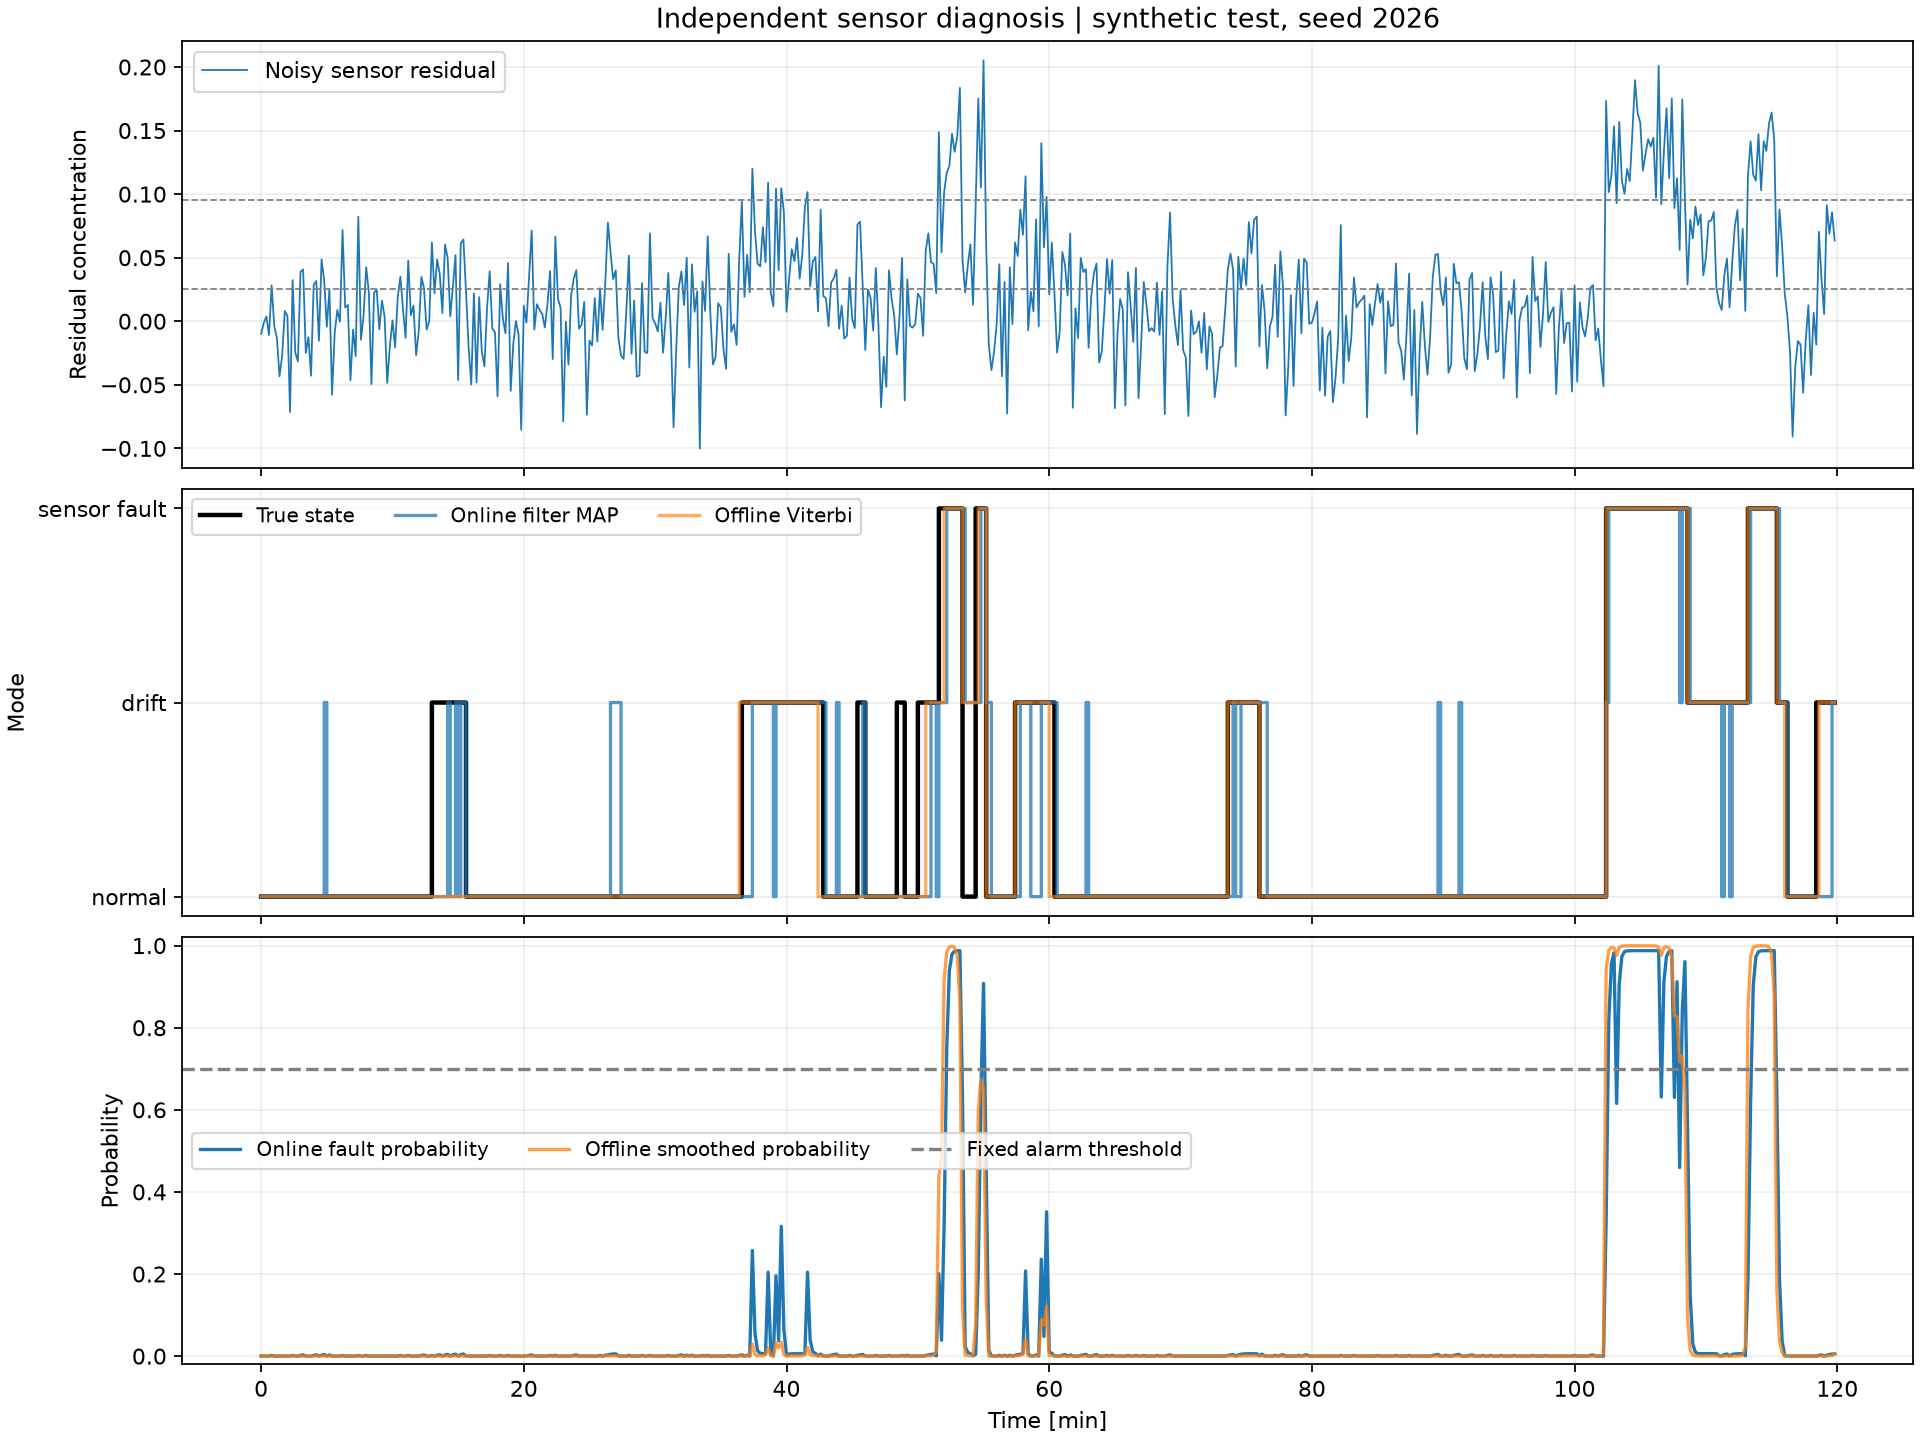

In [5]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / "laboratories/09-markov-hidden-state-diagnosis/results/diagnosis.png")))

## 4. Causal supervision with model mismatch

Both PI loops see the same latent sensor modes and noise. The compensated loop additionally propagates a nominal tank model from its known initial state and past applied inputs. It subtracts the posterior-weighted calibration bias from the current measurement. Only forward filtering enters this controller. The second case changes the true residence time from 10 to 14 min, while the predictor remains at 10 min; this confounds model error with sensor faults.

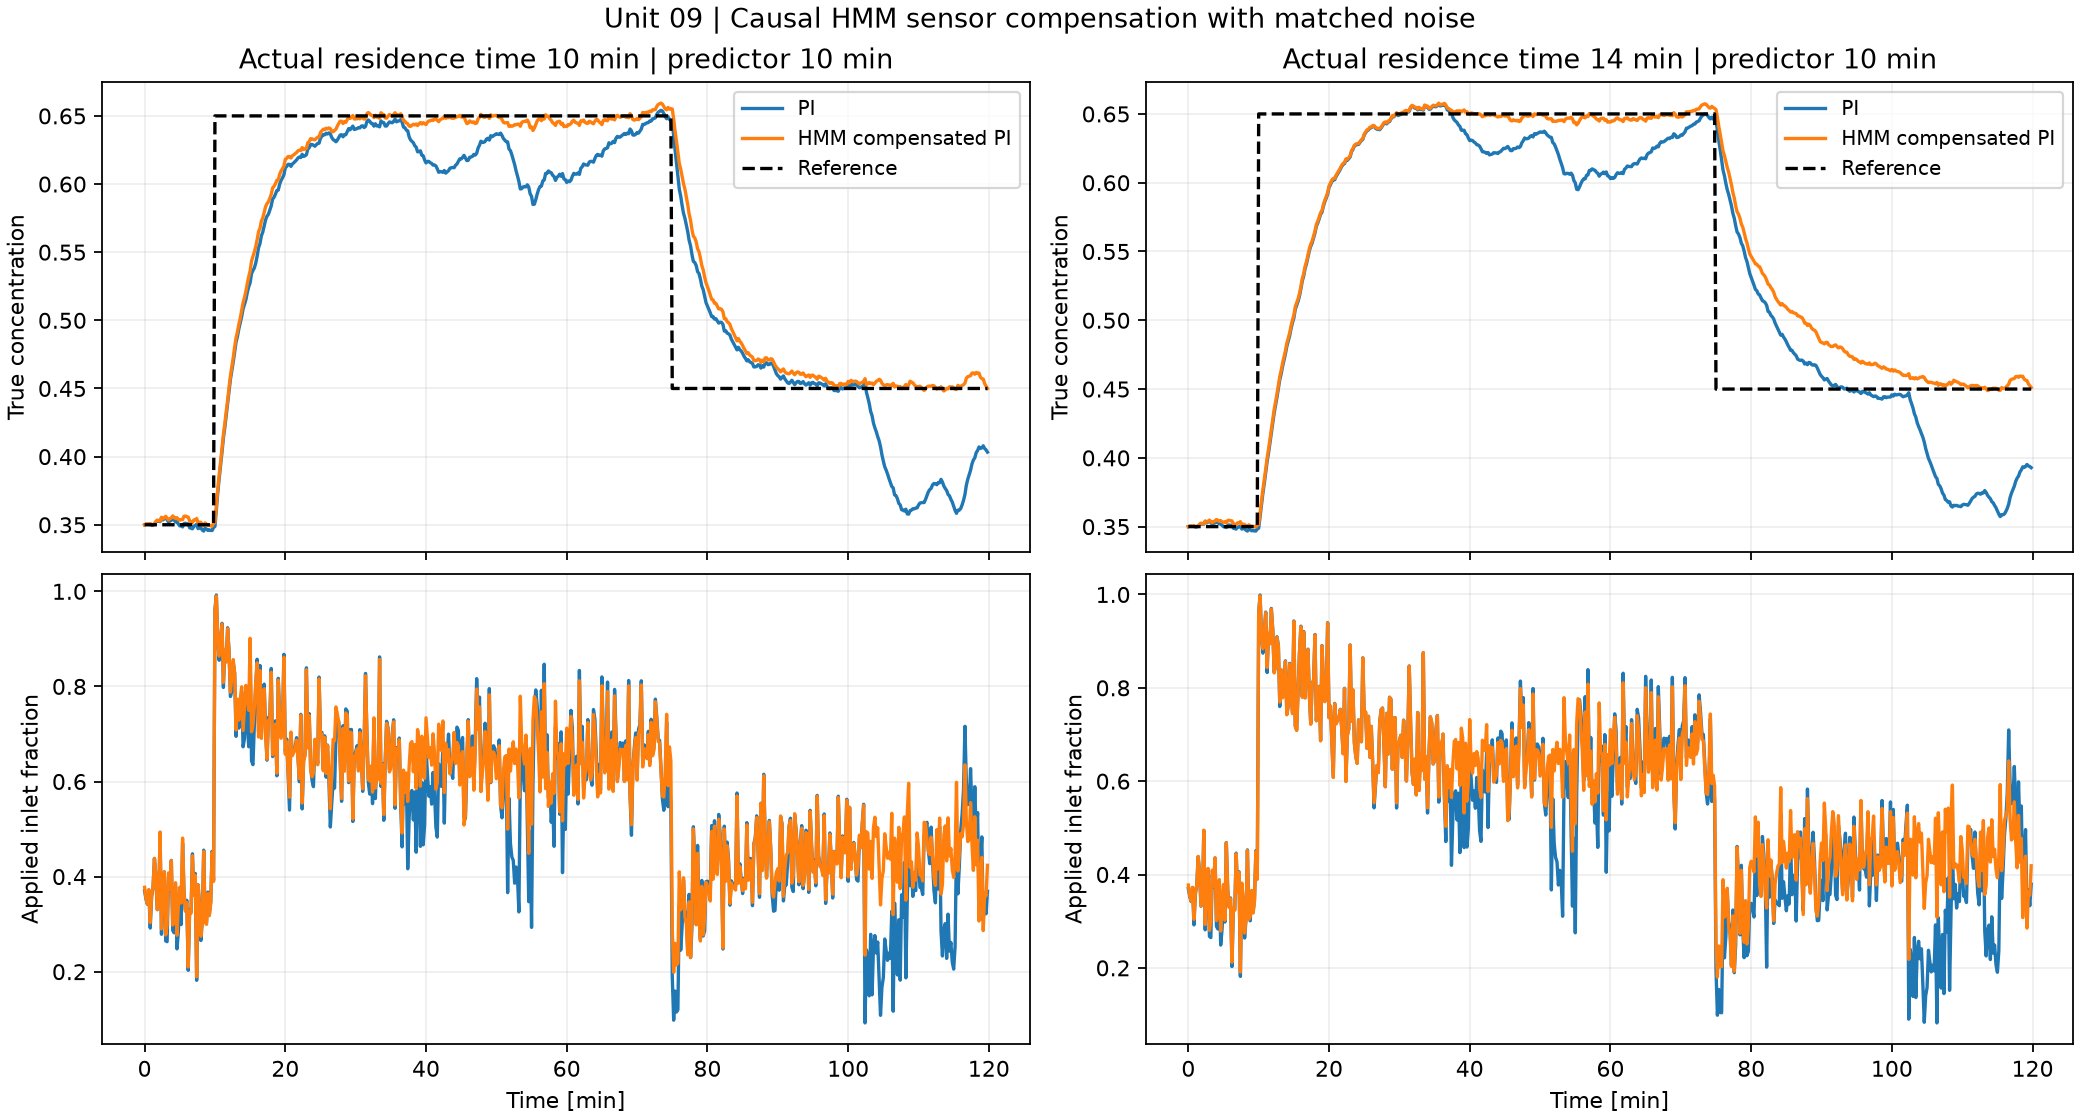

PI, tau=10 IAE = 4.80976 movement = 50.47655
HMM compensated PI, tau=10 IAE = 2.83416 movement = 45.57868
PI, tau=14 IAE = 5.0893 movement = 50.20023
HMM compensated PI, tau=14 IAE = 3.62741 movement = 45.9644


In [6]:
display(Image(filename=str(ROOT / "laboratories/09-markov-hidden-state-diagnosis/results/comparison.png")))
for row in result["summary"]["control"]:
    print(row["policy"], "IAE =", round(row["iae"], 5), "movement =", round(row["total_variation"], 5))

## 5. Investigate

1. Explain why the recoverable chain has a stationary fault probability below one but eventual first-fault probability one.
2. Replace the fault row by an absorbing row; distinguish first passage from stationary behavior.
3. Explain why offline estimates cannot be used as real-time controller inputs.
4. Vary the alarm threshold using calibration data, then freeze it before generating a new test.
5. Discuss emission dependence under model mismatch and the information advantage of the compensated controller.

[Lesson](../../course/09-markov-hidden-state-diagnosis/lesson.md) · [Problems](../../problem-sets/09-markov-hidden-state-diagnosis/exercises.md) · [Worked solutions](../../problem-sets/09-markov-hidden-state-diagnosis/solutions.md) · [Native MATLAB/Octave](../../matlab/README.md)